In [2]:
library(GenomicRanges)
library(dplyr)

# ============================================================
# 1. 读取 ROSE Super-enhancer table
# ============================================================

HTY <- read.table(
    "HTY-H3K27ac_enhancer_SuperEnhancers.table.txt",
    header = TRUE,
    sep = "\t",
    check.names = FALSE,
    stringsAsFactors = FALSE
)

HY <- read.table(
    "HY-H3K27ac_enhancer_SuperEnhancers.table.txt",
    header = TRUE,
    sep = "\t",
    check.names = FALSE,
    stringsAsFactors = FALSE
)

# 查看列名
print(colnames(HTY))
print(colnames(HY))


# ============================================================
# 2. 只保留 Super-enhancer
# ============================================================

HTY_SE <- HTY %>%
    filter(isSuper == 1)

HY_SE <- HY %>%
    filter(isSuper == 1)

cat("HTY Super-enhancer:", nrow(HTY_SE), "\n")
cat("HY Super-enhancer:", nrow(HY_SE), "\n")


# ============================================================
# 3. 构建 GRanges
# ============================================================

HTY_gr <- GRanges(
    seqnames = HTY_SE$CHROM,
    ranges = IRanges(
        start = HTY_SE$START,
        end = HTY_SE$STOP
    )
)

HY_gr <- GRanges(
    seqnames = HY_SE$CHROM,
    ranges = IRanges(
        start = HY_SE$START,
        end = HY_SE$STOP
    )
)


# ============================================================
# 4. 找到所有 overlap
# ============================================================

hits <- findOverlaps(
    HTY_gr,
    HY_gr,
    ignore.strand = TRUE
)

q <- queryHits(hits)
s <- subjectHits(hits)


# ============================================================
# 5. 计算 reciprocal overlap
# ============================================================

overlap_gr <- pintersect(
    HTY_gr[q],
    HY_gr[s]
)

overlap_width <- width(overlap_gr)

HTY_width <- width(HTY_gr[q])
HY_width  <- width(HY_gr[s])

HTY_fraction <- overlap_width / HTY_width
HY_fraction  <- overlap_width / HY_width


# ============================================================
# 6. reciprocal overlap >= 50%
# ============================================================

shared_hits <- data.frame(
    HTY_index = q,
    HY_index = s,
    overlap = overlap_width,
    HTY_fraction = HTY_fraction,
    HY_fraction = HY_fraction
) %>%
    filter(
        HTY_fraction >= 0.5,
        HY_fraction >= 0.5
    )

cat(
    "Shared SE pairs:",
    nrow(shared_hits),
    "\n"
)


# ============================================================
# 7. 找 HTY-specific 和 HY-specific
# ============================================================

HTY_shared_index <- unique(
    shared_hits$HTY_index
)

HY_shared_index <- unique(
    shared_hits$HY_index
)

HTY_specific_index <- setdiff(
    seq_along(HTY_gr),
    HTY_shared_index
)

HY_specific_index <- setdiff(
    seq_along(HY_gr),
    HY_shared_index
)

HTY_specific <- HTY_SE[
    HTY_specific_index,
]

HY_specific <- HY_SE[
    HY_specific_index,
]


# ============================================================
# 8. 输出结果
# ============================================================

write.table(
    HTY_specific,
    "HTY_specific_SuperEnhancer.txt",
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)

write.table(
    HY_specific,
    "HY_specific_SuperEnhancer.txt",
    sep = "\t",
    quote = FALSE,
    row.names = FALSE
)


cat(
    "HTY-specific SE:",
    nrow(HTY_specific),
    "\n"
)

cat(
    "HY-specific SE:",
    nrow(HY_specific),
    "\n"
)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:GenomicRanges’:

    intersect, setdiff, union


The following object is masked from ‘package:GenomeInfoDb’:

    intersect


The following objects are masked from ‘package:IRanges’:

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from ‘package:S4Vectors’:

    first, intersect, rename, setdiff, setequal, union


The following objects are masked from ‘package:BiocGenerics’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




[1] "REGION_ID"                         "CHROM"                            
[3] "START"                             "STOP"                             
[5] "NUM_LOCI"                          "CONSTITUENT_SIZE"                 
[7] "HTY.ovary.H3K27ac.merged.sort.bam" "enhancerRank"                     
[9] "isSuper"                          
[1] "REGION_ID"                        "CHROM"                           
[3] "START"                            "STOP"                            
[5] "NUM_LOCI"                         "CONSTITUENT_SIZE"                
[7] "HY.ovary.H3K27ac.merged.sort.bam" "enhancerRank"                    
[9] "isSuper"                         
HTY Super-enhancer: 108 
HY Super-enhancer: 97 


Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': NW_014643809.1, NW_014641844.1, NW_014640458.1, NW_014641368.1, NW_014639818.1, NW_014642137.1, NW_014640362.1, NC_019474.2, NC_019481.2
  - in 'y': NW_014642044.1, NC_019469.2, NW_014640219.1
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning).”
Warning message in .merge_two_Seqinfo_objects(x, y):
“Each of the 2 combined objects has sequence levels not in the other:
  - in 'x': NW_014643809.1, NW_014641844.1, NW_014640458.1, NW_014641368.1, NW_014639818.1, NW_014642137.1, NW_014640362.1, NC_019474.2, NC_019481.2
  - in 'y': NW_014642044.1, NC_019469.2, NW_014640219.1
  Make sure to always combine/compare objects based on the same reference
  genome (use suppressWarnings() to suppress this warning).”


Shared SE pairs: 77 
HTY-specific SE: 31 
HY-specific SE: 20 


In [ ]:
library(eulerr)
library(grid)

venn_data <- c(
  "Hetian Sheep" = 31,
  "Hu Sheep" = 20,
  "Hetian Sheep&Hu Sheep" = 77
)

fit <- euler(venn_data)

pdf('HTY_HY_SuperEnhancer_Venn.pdf')
plot(
  fit,
  fills = c("#1eb5b8", "#eb746a"),
  alpha = 0.55,
  edges = TRUE,
  edge_width = 1,
  quantities = list(
    cex = 1.3,
    font = 2
  ),
  labels = list(
    cex = 1.2,
    font = 2
  )
)
dev.off()

pdf 
  2

In [7]:
import pandas as pd

# ============================================================
# 1. 输入文件
# ============================================================

gwas_bed = "/home/hnadmin/data/yangshuju/result/ovary/gwas_LD_Oar_v4.bed"

hy_se_file = "HY-H3K27ac_enhancer_SuperEnhancers.table.txt"
hty_se_file = "HTY-H3K27ac_enhancer_SuperEnhancers.table.txt"

hy_output = "HY_SE_GWAS_LD_overlap.tsv"
hty_output = "HTY_SE_GWAS_LD_overlap.tsv"


# ============================================================
# 2. 读取 GWAS / LD BED
# ============================================================

gwas = pd.read_csv(
    gwas_bed,
    sep="\t",
    header=None
)

print("GWAS BED columns:", gwas.shape[1])
print("Number of GWAS/LD regions:", len(gwas))

# 确保只有前三列
gwas = gwas.iloc[:, :3].copy()

gwas.columns = [
    "GWAS_chr",
    "GWAS_start",
    "GWAS_end"
]

# 给每个 GWAS/LD region 一个 ID
gwas["GWAS_ID"] = [
    f"GWAS_{i+1}"
    for i in range(len(gwas))
]

print("\nGWAS/LD example:")
print(gwas.head())


# ============================================================
# 3. 读取 Super-enhancer
# ============================================================

def read_super_enhancer(se_file):

    se = pd.read_csv(
        se_file,
        sep="\t",
        comment="#"
    )

    print("\nReading:", se_file)

    print(
        "Total ROSE regions:",
        len(se)
    )

    # 只保留 Super-enhancer
    se = se[
        se["isSuper"] == 1
    ].copy()

    print(
        "Super-enhancers:",
        len(se)
    )

    # 只保留必要信息
    se = se[
        [
            "REGION_ID",
            "CHROM",
            "START",
            "STOP",
            "NUM_LOCI",
            "CONSTITUENT_SIZE",
            "enhancerRank"
        ]
    ].copy()

    se.columns = [
        "SE_ID",
        "SE_chr",
        "SE_start",
        "SE_end",
        "NUM_LOCI",
        "CONSTITUENT_SIZE",
        "enhancerRank"
    ]

    return se


# ============================================================
# 4. 查找 GWAS/LD 与 SE overlap
# ============================================================

def find_overlap(gwas, se):

    results = []

    for chrom, gwas_chr in gwas.groupby(
        "GWAS_chr"
    ):

        se_chr = se[
            se["SE_chr"] == chrom
        ].copy()

        if len(se_chr) == 0:
            continue

        # ----------------------------------------------------
        # 遍历 GWAS/LD region
        # ----------------------------------------------------

        for _, gwas_row in gwas_chr.iterrows():

            gwas_start = gwas_row[
                "GWAS_start"
            ]

            gwas_end = gwas_row[
                "GWAS_end"
            ]

            gwas_id = gwas_row[
                "GWAS_ID"
            ]

            # ------------------------------------------------
            # 判断区间是否 overlap
            #
            # 两个区间：
            #
            # GWAS: start ---- end
            # SE:       start ---- end
            #
            # overlap:
            # SE_start < GWAS_end
            # &&
            # SE_end > GWAS_start
            # ------------------------------------------------

            overlap = se_chr[
                (
                    se_chr["SE_start"]
                    < gwas_end
                )
                &
                (
                    se_chr["SE_end"]
                    > gwas_start
                )
            ].copy()

            if len(overlap) == 0:
                continue

            # ------------------------------------------------
            # 保存每一个 overlap pair
            # ------------------------------------------------

            for _, se_row in overlap.iterrows():

                # overlap 长度
                overlap_start = max(
                    gwas_start,
                    se_row["SE_start"]
                )

                overlap_end = min(
                    gwas_end,
                    se_row["SE_end"]
                )

                overlap_length = (
                    overlap_end -
                    overlap_start
                )

                # SE center
                se_center = (
                    se_row["SE_start"] +
                    se_row["SE_end"]
                ) / 2

                # GWAS center
                gwas_center = (
                    gwas_start +
                    gwas_end
                ) / 2

                results.append({

                    "GWAS_ID":
                        gwas_id,

                    "GWAS_chr":
                        chrom,

                    "GWAS_start":
                        gwas_start,

                    "GWAS_end":
                        gwas_end,

                    "SE_ID":
                        se_row["SE_ID"],

                    "SE_chr":
                        se_row["SE_chr"],

                    "SE_start":
                        se_row["SE_start"],

                    "SE_end":
                        se_row["SE_end"],

                    "SE_length":
                        se_row["SE_end"]
                        - se_row["SE_start"],

                    "overlap_length":
                        overlap_length,

                    "SE_overlap_fraction":
                        overlap_length /
                        (
                            se_row["SE_end"]
                            -
                            se_row["SE_start"]
                        ),

                    "GWAS_overlap_fraction":
                        overlap_length /
                        (
                            gwas_end
                            -
                            gwas_start
                        ),

                    "NUM_LOCI":
                        se_row["NUM_LOCI"],

                    "CONSTITUENT_SIZE":
                        se_row["CONSTITUENT_SIZE"],

                    "enhancerRank":
                        se_row["enhancerRank"],

                    "distance_GWAS_center_to_SE_center":
                        gwas_center -
                        se_center
                })

    return pd.DataFrame(results)


# ============================================================
# 5. HY Super-enhancer
# ============================================================

hy_se = read_super_enhancer(
    hy_se_file
)

hy_overlap = find_overlap(
    gwas,
    hy_se
)

hy_overlap.to_csv(
    hy_output,
    sep="\t",
    index=False
)


# ============================================================
# 6. HTY Super-enhancer
# ============================================================

hty_se = read_super_enhancer(
    hty_se_file
)

hty_overlap = find_overlap(
    gwas,
    hty_se
)

hty_overlap.to_csv(
    hty_output,
    sep="\t",
    index=False
)


# ============================================================
# 7. 统计
# ============================================================

print("\n========================================")
print("HY Super-enhancer")
print("========================================")

print(
    "GWAS/LD regions:",
    len(gwas)
)

print(
    "GWAS-SE overlap pairs:",
    len(hy_overlap)
)

print(
    "Unique GWAS/LD regions overlapping SE:",
    hy_overlap["GWAS_ID"].nunique()
    if len(hy_overlap) > 0 else 0
)

print(
    "Unique Super-enhancers containing GWAS/LD:",
    hy_overlap["SE_ID"].nunique()
    if len(hy_overlap) > 0 else 0
)


print("\n========================================")
print("HTY Super-enhancer")
print("========================================")

print(
    "GWAS/LD regions:",
    len(gwas)
)

print(
    "GWAS-SE overlap pairs:",
    len(hty_overlap)
)

print(
    "Unique GWAS/LD regions overlapping SE:",
    hty_overlap["GWAS_ID"].nunique()
    if len(hty_overlap) > 0 else 0
)

print(
    "Unique Super-enhancers containing GWAS/LD:",
    hty_overlap["SE_ID"].nunique()
    if len(hty_overlap) > 0 else 0
)


print("\nOutput:")
print(hy_output)
print(hty_output)

GWAS BED columns: 3
Number of GWAS/LD regions: 5638

GWAS/LD example:
      GWAS_chr  GWAS_start   GWAS_end GWAS_ID
0  NC_019458.2   226367215  226367216  GWAS_1
1  NC_019458.2   226369480  226369481  GWAS_2
2  NC_019458.2   226416450  226416451  GWAS_3
3  NC_019458.2   226466735  226466736  GWAS_4
4  NC_019458.2   226467816  226467817  GWAS_5

Reading: HY-H3K27ac_enhancer_SuperEnhancers.table.txt
Total ROSE regions: 97
Super-enhancers: 97

Reading: HTY-H3K27ac_enhancer_SuperEnhancers.table.txt
Total ROSE regions: 108
Super-enhancers: 108

HY Super-enhancer
GWAS/LD regions: 5638
GWAS-SE overlap pairs: 0
Unique GWAS/LD regions overlapping SE: 0
Unique Super-enhancers containing GWAS/LD: 0

HTY Super-enhancer
GWAS/LD regions: 5638
GWAS-SE overlap pairs: 0
Unique GWAS/LD regions overlapping SE: 0
Unique Super-enhancers containing GWAS/LD: 0

Output:
HY_SE_GWAS_LD_overlap.tsv
HTY_SE_GWAS_LD_overlap.tsv


In [9]:
import pandas as pd
import numpy as np
import os

# ============================================================
# 1. 输入文件
# ============================================================

hty_file = "HTY_SuperEnhancer_1Mb_all_nearby_genes.tsv"
hy_file  = "HY_SuperEnhancer_1Mb_all_nearby_genes.tsv"

tpm_file = "/home/hnadmin/data/yangshuju/result/ovary/TPM_HTY_HY_result.txt"

outdir = "/home/hnadmin/data/yangshuju/result/ovary/peak/SE_TPM_analysis"
os.makedirs(outdir, exist_ok=True)


# ============================================================
# 2. 读取 SE-nearby gene
# ============================================================

hty = pd.read_csv(hty_file, sep="\t")
hy  = pd.read_csv(hy_file, sep="\t")

print("HTY:", hty.shape)
print("HY :", hy.shape)

print("\nHTY columns:")
print(hty.columns.tolist())

print("\nHY columns:")
print(hy.columns.tolist())



HTY: (982, 17)
HY : (961, 17)

HTY columns:
['SE_ID', 'SE_chr', 'SE_start', 'SE_end', 'SE_length', 'SE_center', 'NUM_LOCI', 'CONSTITUENT_SIZE', 'ROSE_signal', 'enhancerRank', 'gene_id', 'gene_symbol', 'strand', 'TSS', 'distance_to_TSS', 'distance_to_TSS_abs', 'relative_position']

HY columns:
['SE_ID', 'SE_chr', 'SE_start', 'SE_end', 'SE_length', 'SE_center', 'NUM_LOCI', 'CONSTITUENT_SIZE', 'ROSE_signal', 'enhancerRank', 'gene_id', 'gene_symbol', 'strand', 'TSS', 'distance_to_TSS', 'distance_to_TSS_abs', 'relative_position']


In [11]:
import pandas as pd
import numpy as np
import os

# ============================================================
# 1. 文件
# ============================================================

hty_file = "HTY_SuperEnhancer_1Mb_all_nearby_genes.tsv"
hy_file  = "HY_SuperEnhancer_1Mb_all_nearby_genes.tsv"

tpm_file = "/home/hnadmin/data/yangshuju/result/ovary/TPM_HTY_HY_result.txt"

outdir = "/home/hnadmin/data/yangshuju/result/ovary/peak/SE_TPM_analysis"
os.makedirs(outdir, exist_ok=True)


# ============================================================
# 2. 读取
# ============================================================

hty = pd.read_csv(hty_file, sep="\t")
hy  = pd.read_csv(hy_file, sep="\t")

gene_tpm = pd.read_csv(tpm_file, sep="\t")

gene_tpm = gene_tpm[
    ["Geneid", "HTY_mean_TPM", "HY_mean_TPM"]
].copy()


# ============================================================
# 3. Gene ID 标准化
# ============================================================

def clean_gene_id(x):
    return (
        x.astype(str)
         .str.strip()
         .str.replace(r"\.\d+$", "", regex=True)
    )


hty["gene_id_clean"] = clean_gene_id(hty["gene_id"])
hy["gene_id_clean"] = clean_gene_id(hy["gene_id"])
gene_tpm["Geneid_clean"] = clean_gene_id(gene_tpm["Geneid"])


# 防止 TPM 中重复 gene ID
gene_tpm = gene_tpm.drop_duplicates(
    subset="Geneid_clean"
)


# ============================================================
# 4. 给两个表加入 TPM
# ============================================================

tpm_cols = [
    "Geneid_clean",
    "HTY_mean_TPM",
    "HY_mean_TPM"
]

hty = hty.merge(
    gene_tpm[tpm_cols],
    left_on="gene_id_clean",
    right_on="Geneid_clean",
    how="left"
)

hy = hy.merge(
    gene_tpm[tpm_cols],
    left_on="gene_id_clean",
    right_on="Geneid_clean",
    how="left"
)


# ============================================================
# 5. 计算基因表达差异
# ============================================================

pseudo = 0.1

for df in [hty, hy]:

    df["log2_HTY_HY_TPM"] = np.log2(
        (df["HTY_mean_TPM"] + pseudo) /
        (df["HY_mean_TPM"] + pseudo)
    )

    df["TPM_difference"] = (
        df["HTY_mean_TPM"] -
        df["HY_mean_TPM"]
    )

    df["higher_expression"] = np.where(
        df["HTY_mean_TPM"] > df["HY_mean_TPM"],
        "HTY",
        np.where(
            df["HTY_mean_TPM"] < df["HY_mean_TPM"],
            "HY",
            "Equal"
        )
    )


# ============================================================
# 6. 保存带 TPM 的原始结果
# ============================================================

hty.to_csv(
    os.path.join(
        outdir,
        "HTY_SuperEnhancer_1Mb_all_nearby_genes_TPM.tsv"
    ),
    sep="\t",
    index=False
)

hy.to_csv(
    os.path.join(
        outdir,
        "HY_SuperEnhancer_1Mb_all_nearby_genes_TPM.tsv"
    ),
    sep="\t",
    index=False
)


# ============================================================
# 7. 检查 TPM 匹配率
# ============================================================

print("\n========== TPM matching ==========")

print(
    "HTY TPM matched:",
    hty["HTY_mean_TPM"].notna().sum(),
    "/",
    len(hty)
)

print(
    "HY TPM matched:",
    hy["HY_mean_TPM"].notna().sum(),
    "/",
    len(hy)
)

print(
    "HTY unique genes:",
    hty["gene_id_clean"].nunique()
)

print(
    "HY unique genes:",
    hy["gene_id_clean"].nunique()
)


# ============================================================
# 8. SE坐标表
# ============================================================

hty_se = (
    hty[
        [
            "SE_ID",
            "SE_chr",
            "SE_start",
            "SE_end",
            "SE_length",
            "SE_center"
        ]
    ]
    .drop_duplicates()
    .copy()
)

hy_se = (
    hy[
        [
            "SE_ID",
            "SE_chr",
            "SE_start",
            "SE_end",
            "SE_length",
            "SE_center"
        ]
    ]
    .drop_duplicates()
    .copy()
)

print("\n========== SE number ==========")

print("HTY SE:", len(hty_se))
print("HY SE :", len(hy_se))


# ============================================================
# 9. 判断两个品种 SE 是否 overlap
#    reciprocal overlap >= 50%
# ============================================================

def reciprocal_overlap(a_start, a_end, b_start, b_end):

    overlap = max(
        0,
        min(a_end, b_end) -
        max(a_start, b_start)
    )

    if overlap == 0:
        return 0, 0, 0

    len_a = a_end - a_start
    len_b = b_end - b_start

    frac_a = overlap / len_a
    frac_b = overlap / len_b

    return overlap, frac_a, frac_b


shared_pairs = []

for i, a in hty_se.iterrows():

    candidates = hy_se[
        hy_se["SE_chr"] == a["SE_chr"]
    ]

    for j, b in candidates.iterrows():

        overlap, frac_a, frac_b = reciprocal_overlap(
            a["SE_start"],
            a["SE_end"],
            b["SE_start"],
            b["SE_end"]
        )

        if frac_a >= 0.5 and frac_b >= 0.5:

            shared_pairs.append({

                "HTY_SE_ID": a["SE_ID"],
                "HY_SE_ID": b["SE_ID"],

                "chr": a["SE_chr"],

                "HTY_start": a["SE_start"],
                "HTY_end": a["SE_end"],

                "HY_start": b["SE_start"],
                "HY_end": b["SE_end"],

                "overlap_length": overlap,

                "HTY_overlap_fraction": frac_a,

                "HY_overlap_fraction": frac_b
            })


shared = pd.DataFrame(shared_pairs)

print("\nShared SE:", len(shared))


# ============================================================
# 10. 获得 specific SE
# ============================================================

hty_shared_ids = set(shared["HTY_SE_ID"])
hy_shared_ids = set(shared["HY_SE_ID"])

hty_specific = hty_se[
    ~hty_se["SE_ID"].isin(hty_shared_ids)
].copy()

hy_specific = hy_se[
    ~hy_se["SE_ID"].isin(hy_shared_ids)
].copy()


print("HTY-specific SE:", len(hty_specific))
print("HY-specific SE :", len(hy_specific))


# ============================================================
# 11. 给 SE 标记类型
# ============================================================

hty_se["SE_group"] = np.where(
    hty_se["SE_ID"].isin(hty_shared_ids),
    "Shared",
    "HTY-specific"
)

hy_se["SE_group"] = np.where(
    hy_se["SE_ID"].isin(hy_shared_ids),
    "Shared",
    "HY-specific"
)


# ============================================================
# 12. 把 SE 类型加入附近基因表
# ============================================================

hty = hty.merge(
    hty_se[["SE_ID", "SE_group"]],
    on="SE_ID",
    how="left"
)

hy = hy.merge(
    hy_se[["SE_ID", "SE_group"]],
    on="SE_ID",
    how="left"
)


# ============================================================
# 13. 保存 SE 分类
# ============================================================

hty_se.to_csv(
    os.path.join(
        outdir,
        "HTY_SE_classification.tsv"
    ),
    sep="\t",
    index=False
)

hy_se.to_csv(
    os.path.join(
        outdir,
        "HY_SE_classification.tsv"
    ),
    sep="\t",
    index=False
)

shared.to_csv(
    os.path.join(
        outdir,
        "Shared_SE_pairs.tsv"
    ),
    sep="\t",
    index=False
)


# ============================================================
# 14. 分别保存三类SE附近基因
# ============================================================

hty_specific_genes = hty[
    hty["SE_group"] == "HTY-specific"
].copy()

hy_specific_genes = hy[
    hy["SE_group"] == "HY-specific"
].copy()

shared_hty_genes = hty[
    hty["SE_group"] == "Shared"
].copy()

shared_hy_genes = hy[
    hy["SE_group"] == "Shared"
].copy()


hty_specific_genes.to_csv(
    os.path.join(
        outdir,
        "HTY_specific_SE_nearby_genes_TPM.tsv"
    ),
    sep="\t",
    index=False
)

hy_specific_genes.to_csv(
    os.path.join(
        outdir,
        "HY_specific_SE_nearby_genes_TPM.tsv"
    ),
    sep="\t",
    index=False
)


# ============================================================
# 15. SE-level表达总结
# ============================================================

def summarize_se_genes(df):

    result = (
        df.groupby(
            ["SE_ID", "SE_group"],
            as_index=False
        )
        .agg(
            nearby_gene_number=("gene_id_clean", "nunique"),

            HTY_mean_TPM=("HTY_mean_TPM", "mean"),
            HY_mean_TPM=("HY_mean_TPM", "mean"),

            HTY_sum_TPM=("HTY_mean_TPM", "sum"),
            HY_sum_TPM=("HY_mean_TPM", "sum"),

            mean_log2_HTY_HY=("log2_HTY_HY_TPM", "mean")
        )
    )

    result["TPM_difference"] = (
        result["HTY_mean_TPM"] -
        result["HY_mean_TPM"]
    )

    result["higher_expression"] = np.where(
        result["HTY_mean_TPM"] >
        result["HY_mean_TPM"],
        "HTY",
        np.where(
            result["HTY_mean_TPM"] <
            result["HY_mean_TPM"],
            "HY",
            "Equal"
        )
    )

    return result


hty_se_summary = summarize_se_genes(hty)
hy_se_summary = summarize_se_genes(hy)


# ============================================================
# 16. 合并 SE summary
# ============================================================

# Shared SE在两个品种中会各有一行
se_summary = pd.concat(
    [
        hty_se_summary,
        hy_se_summary
    ],
    ignore_index=True
)

se_summary.to_csv(
    os.path.join(
        outdir,
        "SE_nearby_gene_TPM_summary.tsv"
    ),
    sep="\t",
    index=False
)


# ============================================================
# 17. 输出统计
# ============================================================

print("\n======================================")
print("SE classification")
print("======================================")

print(
    hty_se["SE_group"].value_counts()
)

print(
    hy_se["SE_group"].value_counts()
)

print("\nResults saved to:")
print(outdir)


========== TPM matching ==========
HTY TPM matched: 982 / 982
HY TPM matched: 961 / 961
HTY unique genes: 918
HY unique genes: 898

========== SE number ==========
HTY SE: 56
HY SE : 47

Shared SE: 34
HTY-specific SE: 22
HY-specific SE : 13

SE classification
SE_group
Shared          34
HTY-specific    22
Name: count, dtype: int64
SE_group
Shared         34
HY-specific    13
Name: count, dtype: int64

Results saved to:
/home/hnadmin/data/yangshuju/result/ovary/peak/SE_TPM_analysis


In [1]:
import pandas as pd 
hty_h3k27ac = pd.read_csv('HTY-H3K27ac_enhancer_SuperEnhancers.table.txt',sep='\t',comment='#')
hy_h3k27ac = pd.read_csv('HY-H3K27ac_enhancer_SuperEnhancers.table.txt',sep='\t',comment='#')


In [3]:
hty_h3k27ac[['CHROM','START','STOP']].to_csv('HTY-H3K27ac_enhancer_SuperEnhancers.bed',sep='\t',index=False,header=False)
hy_h3k27ac[['CHROM','START','STOP']].to_csv('HY-H3K27ac_enhancer_SuperEnhancers.bed',sep='\t',index=False,header=False)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

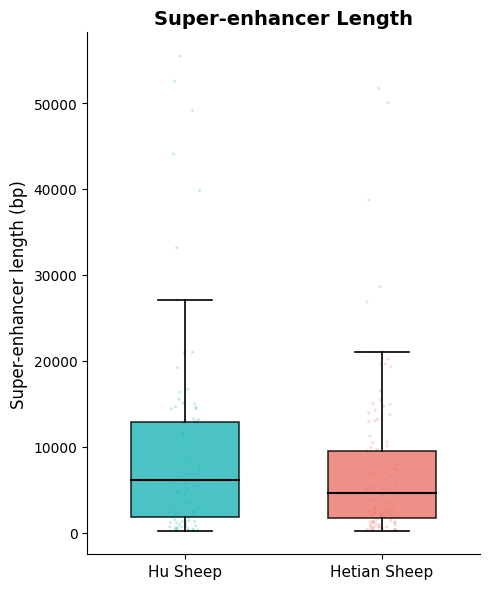

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

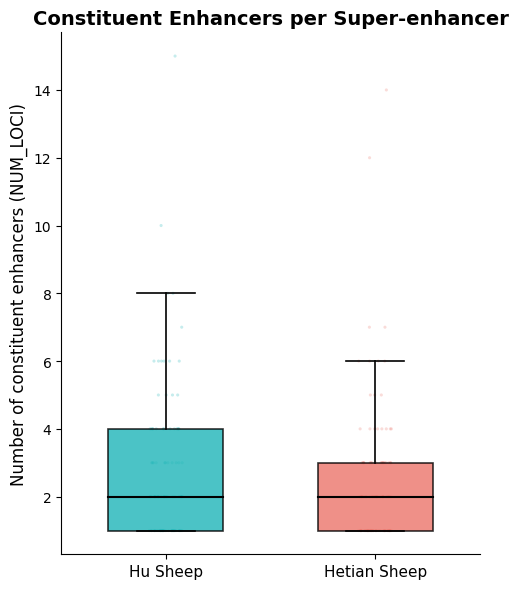


========== Super-enhancer length ==========
Hu Sheep: N = 97 Median = 6097.0 Mean = 9285.350515463917
Hetian Sheep: N = 108 Median = 4624.0 Mean = 7392.333333333333

========== NUM_LOCI ==========
Hu Sheep: N = 97 Median = 2.0 Mean = 2.7938144329896906
Hetian Sheep: N = 108 Median = 2.0 Mean = 2.435185185185185


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. 读取 ROSE Super-enhancer 结果
# ============================================================

hty_h3k27ac = pd.read_csv(
    'HTY-H3K27ac_enhancer_SuperEnhancers.table.txt',
    sep='\t',
    comment='#'
)

hy_h3k27ac = pd.read_csv(
    'HY-H3K27ac_enhancer_SuperEnhancers.table.txt',
    sep='\t',
    comment='#'
)

# ============================================================
# 2. 添加 Breed
# ============================================================

hty_h3k27ac["Breed"] = "Hetian Sheep"
hy_h3k27ac["Breed"] = "Hu Sheep"

# ============================================================
# 3. 计算 Super-enhancer length
#    ROSE 表中使用 STOP - START
# ============================================================

for df in [hty_h3k27ac, hy_h3k27ac]:

    df["START"] = pd.to_numeric(df["START"], errors="coerce")
    df["STOP"] = pd.to_numeric(df["STOP"], errors="coerce")

    df["SE_length"] = df["STOP"] - df["START"]

    df["NUM_LOCI"] = pd.to_numeric(
        df["NUM_LOCI"],
        errors="coerce"
    )

# 去除无效值
hy_length = hy_h3k27ac.loc[
    hy_h3k27ac["SE_length"] > 0,
    "SE_length"
].dropna()

hty_length = hty_h3k27ac.loc[
    hty_h3k27ac["SE_length"] > 0,
    "SE_length"
].dropna()

hy_loci = hy_h3k27ac["NUM_LOCI"].dropna()
hty_loci = hty_h3k27ac["NUM_LOCI"].dropna()


# ============================================================
# 4. 设置字体和 Illustrator 可编辑参数
# ============================================================

plt.rcParams["font.family"] = "Arial"

# PDF 中保留 TrueType 字体
plt.rcParams["pdf.fonttype"] = 42

# SVG 中保留文字为文字对象
plt.rcParams["svg.fonttype"] = "none"

# 品种颜色
breed_colors = {
    "Hu Sheep": "#1eb5b8",
    "Hetian Sheep": "#eb746a"
}


# ============================================================
# 5. 第一张图：Super-enhancer length 箱形图
# ============================================================

fig, ax = plt.subplots(figsize=(5, 6))

data_length = [
    hy_length.values,
    hty_length.values
]

box = ax.boxplot(
    data_length,
    positions=[1, 2],
    widths=0.55,
    patch_artist=True,

    # 显示中位数
    showfliers=False,

    medianprops=dict(
        color="black",
        linewidth=1.5
    ),

    whiskerprops=dict(
        color="black",
        linewidth=1.2
    ),

    capprops=dict(
        color="black",
        linewidth=1.2
    ),

    boxprops=dict(
        linewidth=1.2
    )
)

# 设置箱体颜色
for patch, color in zip(
    box["boxes"],
    [
        breed_colors["Hu Sheep"],
        breed_colors["Hetian Sheep"]
    ]
):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)


# ============================================================
# 添加少量 jitter 点显示实际分布
# ============================================================

rng = np.random.default_rng(123)

# 为了避免超级增强子很多导致图过于拥挤，
# 最多显示 2000 个点
def get_points(values, max_points=2000):

    values = np.asarray(values)

    if len(values) > max_points:
        values = rng.choice(
            values,
            size=max_points,
            replace=False
        )

    return values


hy_plot = get_points(hy_length)
hty_plot = get_points(hty_length)

ax.scatter(
    np.ones(len(hy_plot)) +
    rng.uniform(-0.08, 0.08, len(hy_plot)),
    hy_plot,
    s=5,
    alpha=0.25,
    color=breed_colors["Hu Sheep"],
    edgecolors="none"
)

ax.scatter(
    np.ones(len(hty_plot)) * 2 +
    rng.uniform(-0.08, 0.08, len(hty_plot)),
    hty_plot,
    s=5,
    alpha=0.25,
    color=breed_colors["Hetian Sheep"],
    edgecolors="none"
)


# ============================================================
# 坐标轴
# ============================================================

ax.set_xticks([1, 2])
ax.set_xticklabels(
    ["Hu Sheep", "Hetian Sheep"],
    fontsize=11
)

ax.set_ylabel(
    "Super-enhancer length (bp)",
    fontsize=12
)

ax.set_title(
    "Super-enhancer Length",
    fontsize=14,
    fontweight="bold"
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()


# ============================================================
# 保存
# ============================================================

plt.savefig(
    "HY_HTY_super_enhancer_length_boxplot.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "HY_HTY_super_enhancer_length_boxplot.svg",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. 第二张图：
#    每个 Super-enhancer 中包含的普通 enhancer 数量
#    使用 ROSE 表中的 NUM_LOCI
# ============================================================

fig, ax = plt.subplots(figsize=(5, 6))

data_loci = [
    hy_loci.values,
    hty_loci.values
]

box = ax.boxplot(
    data_loci,
    positions=[1, 2],
    widths=0.55,
    patch_artist=True,
    showfliers=False,

    medianprops=dict(
        color="black",
        linewidth=1.5
    ),

    whiskerprops=dict(
        color="black",
        linewidth=1.2
    ),

    capprops=dict(
        color="black",
        linewidth=1.2
    ),

    boxprops=dict(
        linewidth=1.2
    )
)

# 设置颜色
for patch, color in zip(
    box["boxes"],
    [
        breed_colors["Hu Sheep"],
        breed_colors["Hetian Sheep"]
    ]
):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)


# ============================================================
# 添加 jitter 点
# ============================================================

hy_plot = get_points(hy_loci)
hty_plot = get_points(hty_loci)

ax.scatter(
    np.ones(len(hy_plot)) +
    rng.uniform(-0.08, 0.08, len(hy_plot)),
    hy_plot,
    s=5,
    alpha=0.25,
    color=breed_colors["Hu Sheep"],
    edgecolors="none"
)

ax.scatter(
    np.ones(len(hty_plot)) * 2 +
    rng.uniform(-0.08, 0.08, len(hty_plot)),
    hty_plot,
    s=5,
    alpha=0.25,
    color=breed_colors["Hetian Sheep"],
    edgecolors="none"
)


# ============================================================
# 坐标轴
# ============================================================

ax.set_xticks([1, 2])

ax.set_xticklabels(
    ["Hu Sheep", "Hetian Sheep"],
    fontsize=11
)

ax.set_ylabel(
    "Number of constituent enhancers (NUM_LOCI)",
    fontsize=12
)

ax.set_title(
    "Constituent Enhancers per Super-enhancer",
    fontsize=14,
    fontweight="bold"
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()


# ============================================================
# 保存
# ============================================================

plt.savefig(
    "HY_HTY_super_enhancer_NUM_LOCI_boxplot.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "HY_HTY_super_enhancer_NUM_LOCI_boxplot.svg",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 7. 输出基本统计信息
# ============================================================

print("\n========== Super-enhancer length ==========")

print(
    "Hu Sheep:",
    "N =", len(hy_length),
    "Median =", hy_length.median(),
    "Mean =", hy_length.mean()
)

print(
    "Hetian Sheep:",
    "N =", len(hty_length),
    "Median =", hty_length.median(),
    "Mean =", hty_length.mean()
)


print("\n========== NUM_LOCI ==========")

print(
    "Hu Sheep:",
    "N =", len(hy_loci),
    "Median =", hy_loci.median(),
    "Mean =", hy_loci.mean()
)

print(
    "Hetian Sheep:",
    "N =", len(hty_loci),
    "Median =", hty_loci.median(),
    "Mean =", hty_loci.mean()
)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

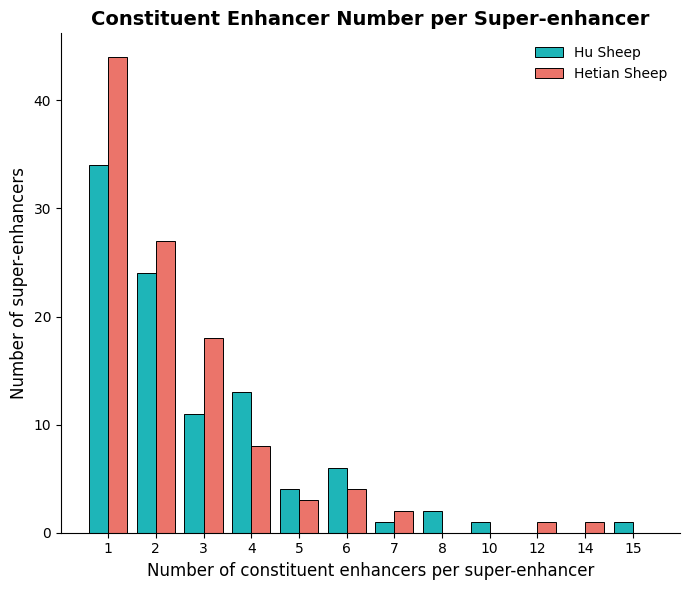

In [9]:
# ============================================================
# 第二张图：
# X轴 = 每个Super-enhancer包含的普通enhancer数量（NUM_LOCI）
# Y轴 = Super-enhancer数量
# ============================================================

# 统计每种 NUM_LOCI 对应的 Super-enhancer 数量
hy_num_loci_count = (
    hy_h3k27ac["NUM_LOCI"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

hty_num_loci_count = (
    hty_h3k27ac["NUM_LOCI"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

# 所有 NUM_LOCI
all_num_loci = sorted(
    set(hy_num_loci_count.index) |
    set(hty_num_loci_count.index)
)

# 补齐没有出现的 NUM_LOCI
hy_counts = [
    hy_num_loci_count.get(x, 0)
    for x in all_num_loci
]

hty_counts = [
    hty_num_loci_count.get(x, 0)
    for x in all_num_loci
]


# ============================================================
# 绘图
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

x = np.arange(len(all_num_loci))
width = 0.4

ax.bar(
    x - width / 2,
    hy_counts,
    width=width,
    label="Hu Sheep",
    color=breed_colors["Hu Sheep"],
    edgecolor="black",
    linewidth=0.7
)

ax.bar(
    x + width / 2,
    hty_counts,
    width=width,
    label="Hetian Sheep",
    color=breed_colors["Hetian Sheep"],
    edgecolor="black",
    linewidth=0.7
)


# ============================================================
# 坐标轴
# ============================================================

ax.set_xlabel(
    "Number of constituent enhancers per super-enhancer",
    fontsize=12
)

ax.set_ylabel(
    "Number of super-enhancers",
    fontsize=12
)

ax.set_title(
    "Constituent Enhancer Number per Super-enhancer",
    fontsize=14,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(
    all_num_loci,
    fontsize=10
)

ax.tick_params(
    axis="y",
    labelsize=10
)

ax.legend(
    frameon=False,
    fontsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()


# ============================================================
# 保存
# ============================================================

plt.savefig(
    "HY_HTY_super_enhancer_NUM_LOCI_distribution.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "HY_HTY_super_enhancer_NUM_LOCI_distribution.svg",
    bbox_inches="tight"
)

plt.show()